# 3 · Is diffusion enough?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/albgirelli/Gonzo_viewer/blob/main/notebooks/03_diffusion_depth.ipynb)

If the tracer only *diffuses* into the brain from the CSF around it, the concentration at depth $x$
below the surface should follow
$$\partial_t c = D\,\partial_{xx} c,\qquad c(0,t) = \alpha\, c_{\text{CSF}}(t),$$
where $c_{\text{CSF}}(t)$ is measured just outside the brain and $\alpha$ accounts for the fact that
the tracer can only access the extracellular space (roughly 20% of tissue).

Molecular diffusion of gadobutrol in brain tissue is expected to be about
$D \approx 1.2\times10^{-4}$ mm²/s (free diffusion $3.8\times10^{-4}$ mm²/s slowed by tortuosity).
Let us fit $D$ and $\alpha$ to the measured depth profiles.

In [1]:
# Setup: works both locally (inside the cloned repository) and on Google Colab.
from pathlib import Path
import subprocess

REPO_URL = "https://github.com/albgirelli/Gonzo_viewer"
if Path("../data/regions.csv").exists():
    DATA = Path("../data")
else:
    if not Path("Gonzo_viewer").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL], check=True)
    DATA = Path("Gonzo_viewer/data")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares

depth = pd.read_csv(DATA / "depth_profiles.csv")
P = depth.pivot(index="depth_mm", columns="hours_after_injection", values="mean_concentration_mmol_per_L")
hours = P.columns.values
c_csf = P.loc[-1].values            # CSF concentration 1 mm outside the brain
obs_depth = np.arange(1, 16)
obs = P.loc[obs_depth].values       # tissue concentration at 1..15 mm depth
x = np.arange(0, 40.01, 0.5)        # computational grid (mm), no-flux at 40 mm

In [3]:
def simulate(D, alpha, k=0.0):
    """Diffusion (+ optional first-order clearance k, 1/h) into a half-space; D in mm²/s."""
    dx = x[1] - x[0]
    bc = lambda t: alpha * np.interp(t, hours, c_csf)
    def rhs(t, c):
        full = np.concatenate([[bc(t)], c, [c[-1]]])
        return D * 3600 * (full[2:] - 2 * full[1:-1] + full[:-2]) / dx**2 - k * c
    sol = solve_ivp(rhs, (0, hours[-1]), np.zeros(len(x) - 1), t_eval=hours, method="BDF")
    c = np.vstack([[bc(t) for t in hours], sol.y])
    return np.array([np.interp(obs_depth, x, c[:, j]) for j in range(len(hours))]).T

def fit(fixed_D=None):
    def res(p):
        D = fixed_D if fixed_D else np.exp(p[1])
        return (simulate(D, np.exp(p[0])) - obs)[:, 1:].ravel()
    p0 = [np.log(0.5)] + ([] if fixed_D else [np.log(1.2e-4)])
    r = least_squares(res, p0)
    return np.exp(r.x), r.cost

(alpha_m, ), cost_m = fit(fixed_D=1.2e-4)
(alpha_f, D_f), cost_f = fit()
print(f"molecular D = 1.2e-4 mm²/s : alpha = {alpha_m:.2f}, misfit = {cost_m:.2e}")
print(f"fitted    D = {D_f:.1e} mm²/s : alpha = {alpha_f:.2f}, misfit = {cost_f:.2e}  ({D_f / 1.2e-4:.1f}× molecular)")

molecular D = 1.2e-4 mm²/s : alpha = 0.60, misfit = 2.00e-03
fitted    D = 3.5e-04 mm²/s : alpha = 0.46, misfit = 6.41e-04  (2.9× molecular)


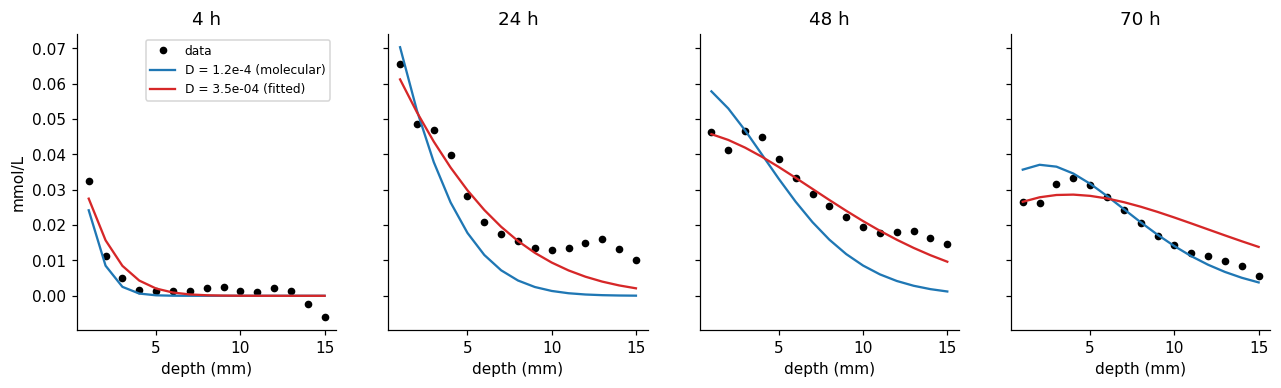

In [4]:
fig, ax = plt.subplots(1, 4, figsize=(14, 3.5), sharey=True)
pred_m, pred_f = simulate(1.2e-4, alpha_m), simulate(D_f, alpha_f)
for j, a in enumerate(ax):
    a.plot(obs_depth, obs[:, j + 1], "ko", ms=4, label="data")
    a.plot(obs_depth, pred_m[:, j + 1], "C0", label="D = 1.2e-4 (molecular)")
    a.plot(obs_depth, pred_f[:, j + 1], "C3", label=f"D = {D_f:.1e} (fitted)")
    a.set_title(f"{hours[j + 1]:.0f} h"); a.set_xlabel("depth (mm)")
ax[0].set_ylabel("mmol/L"); ax[0].legend(fontsize=8);

## Discuss and extend
* The fitted $D$ is several times larger than molecular diffusion. Is that evidence of **flow** (convection, glymphatic transport), or of something the 1D model ignores: brain folding and curvature, partial volume at the surface, tracer arriving from the ventricles, white matter vs grey matter, …?
* Add **clearance** (`k > 0`) or a **velocity** term $-v\,\partial_x c$. Which model does the data prefer? Use AIC/BIC, cross-validation, or Bayesian model comparison.
* Repeat the analysis **region by region** (from the 3D volumes). Does the apparent $D$ differ between regions?
* How **uncertain** is $D$? What is the smallest flow velocity this data could detect?